# Calidad del agua — Clasificación de potabilidad

**Curso:** Inteligencia Artificial · Universidad Tecnológica de Bolívar
**Metodología:** CRISP-ML(Q) (Studer et al., 2021) · **AutoML:** FLAML · **Trazabilidad:** MLflow
**Modelos:** regresión lineal (modelo de probabilidad lineal), regresión logística, SVM y árbol de decisión

| Fase CRISP-ML(Q) | Sección |
|---|---|
| 1. Entendimiento del negocio y de los datos | Objetivo, calidad de datos, EDA |
| 2. Preparación de datos | Partición, imputación, escalado |
| 3. Modelado | Línea base, **validación de supuestos**, AutoML |
| 4. Evaluación | Métricas vs. criterios de éxito, umbral, robustez |
| 5. Despliegue | Registro del modelo y carga para inferencia |
| 6. Monitoreo y mantenimiento | Deriva de datos y plan de reentrenamiento |

> **Nota:** la variable objetivo `Potability` es binaria (0/1), por lo que el problema es de **clasificación**, no de regresión. La regresión lineal se incluye como *modelo de probabilidad lineal* para contrastar sus supuestos con los de la logística.

## Fase 1 · Entendimiento del negocio y de los datos

### 1.1 Objetivo

**Problema de negocio.** Una empresa de acueducto analiza muestras de agua en laboratorio. Quiere **priorizar qué muestras requieren análisis confirmatorio**, reduciendo el riesgo de declarar potable un agua que no lo es.

**Objetivo de ML.** Clasificación binaria supervisada: estimar la probabilidad de que una muestra sea potable (`Potability = 1`) a partir de 9 parámetros fisicoquímicos.

**Criterios de éxito (definidos antes de modelar):**

| Tipo | Criterio | Umbral |
|---|---|---|
| Principal | ROC-AUC en test | ≥ 0.65 y mayor que la línea base |
| Operativo | Precisión de la clase *Potable* en el umbral elegido | ≥ 0.70 (≤ 30 % de falsos "potable") |
| Robustez | Desviación estándar del AUC en validación cruzada | ≤ 0.03 |
| Reproducibilidad | Datos, parámetros, métricas y modelo registrados en MLflow | 100 % de los runs |

**Restricciones y riesgos:** el modelo **no reemplaza** el laboratorio; debe ser interpretable y libre de fuga de datos (*data leakage*).

### 1.2 Configuración del entorno y rutas de MLflow (subcarpeta `mlops/`)

In [1]:
# Si falla `from flaml import AutoML`, instale los extras: pip install "flaml[automl]"
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import mlflow
from flaml import AutoML

SEED = 123
DIR_DATA = Path.cwd() / "data"
DIR_MLOPS = Path.cwd() / "mlops"                 # todo lo de MLflow vive aquí
(DIR_MLOPS / "artifacts").mkdir(parents=True, exist_ok=True)

In [2]:
# Backend (SQLite) y artefactos dentro de mlops/
mlflow.set_tracking_uri(f"sqlite:///{(DIR_MLOPS / 'mlflow.db').as_posix()}")
EXP = "water_potability_crispmlq"
if mlflow.get_experiment_by_name(EXP) is None:
    mlflow.create_experiment(EXP, artifact_location=(DIR_MLOPS / "artifacts").as_uri())
mlflow.set_experiment(EXP)
print(mlflow.get_tracking_uri())

2026/10/26 14:40:10 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/26 14:40:10 INFO mlflow.store.db.utils: Updating database tables


sqlite:////home/claude/wq/nb/mlops/mlflow.db


### 1.3 Diccionario de datos

| Variable | Descripción | Unidad | Referencia (OMS/EPA) |
|---|---|---|---|
| `ph` | Balance ácido-base | — | 6.5 – 8.5 |
| `Hardness` | Sales de calcio y magnesio | mg/L | sin límite sanitario |
| `Solids` | Sólidos disueltos totales (TDS) | mg/L | ≤ 1000 |
| `Chloramines` | Desinfectante (cloro + amoníaco) | ppm | ≤ 4 |
| `Sulfate` | Sulfatos | mg/L | ≤ 250 (sabor) |
| `Conductivity` | Conductividad eléctrica | μS/cm | ≤ 400 |
| `Organic_carbon` | Carbono orgánico total | mg/L | ≤ 2 (agua tratada) |
| `Trihalomethanes` | Subproductos de la cloración | μg/L | ≤ 80 |
| `Turbidity` | Material en suspensión | NTU | ≤ 5 |
| `Potability` | **Objetivo:** 1 = potable, 0 = no potable | — | — |

In [3]:
df = pd.read_csv(DIR_DATA / "water_potability.csv")
TARGET = "Potability"
FEATURES = [c for c in df.columns if c != TARGET]
LIMITS = {"ph": (6.5, 8.5), "Solids": (None, 1000), "Chloramines": (None, 4), "Sulfate": (None, 250),
          "Conductivity": (None, 400), "Organic_carbon": (None, 2), "Trihalomethanes": (None, 80), "Turbidity": (None, 5)}
print(df.shape); df.head()

(3276, 10)


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


### 1.4 Verificación de la calidad de los datos

In [4]:
quality = pd.DataFrame({"tipo": df.dtypes, "faltantes_%": df.isna().mean().mul(100).round(1),
                        "únicos": df.nunique(), "min": df.min(), "max": df.max()})
print("Filas duplicadas:", df.duplicated().sum(), "· filas con algún faltante:", f"{df.isna().any(axis=1).mean():.1%}")
quality

Filas duplicadas: 0 · filas con algún faltante: 38.6%


,tipo,faltantes_%,únicos,min,max
ph,float64,15.0,2785,0.000000,14.000000
Hardness,float64,0.0,3276,47.432000,323.124000
Solids,float64,0.0,3276,320.942611,61227.196008
Chloramines,float64,0.0,3276,0.352000,13.127000
Sulfate,float64,23.8,2495,129.000000,481.030642
Conductivity,float64,0.0,3276,181.483754,753.342620
Organic_carbon,float64,0.0,3276,2.200000,28.300000
Trihalomethanes,float64,4.9,3114,0.738000,124.000000
Turbidity,float64,0.0,3276,1.450000,6.739000
Potability,int64,0.0,2,0.000000,1.000000


In [5]:
# % de muestras fuera del rango de referencia, por clase
def fuera_rango(s, lo, hi):
    return ((s < lo) if lo is not None else False) | ((s > hi) if hi is not None else False)
pd.DataFrame({v: df.groupby(TARGET)[v].apply(lambda s: fuera_rango(s.dropna(), *lim).mean())
              for v, lim in LIMITS.items()}).T.mul(100).round(1).add_prefix("clase_")

Potability,clase_0,clase_1
ph,55.8,47.0
Solids,99.9,99.9
Chloramines,97.3,97.2
Sulfate,98.8,95.9
Conductivity,60.1,59.6
Organic_carbon,100.0,100.0
Trihalomethanes,19.2,19.5
Turbidity,9.9,9.2


> **Interpretación.** No hay duplicados; `ph` (15 %), `Sulfate` (24 %) y `Trihalomethanes` (5 %) tienen faltantes y el 39 % de las filas tiene al menos uno. Casi todas las muestras **superan** los límites de `Solids`, `Chloramines`, `Sulfate` y `Organic_carbon`, **incluso las etiquetadas como potables**: ninguna muestra cumple simultáneamente los límites de pH, sólidos, cloraminas y turbidez. Es un **riesgo de calidad de la etiqueta** (posibles datos semisintéticos o unidades distintas) que debe reportarse: limita el desempeño alcanzable.

### 1.5 Variable objetivo

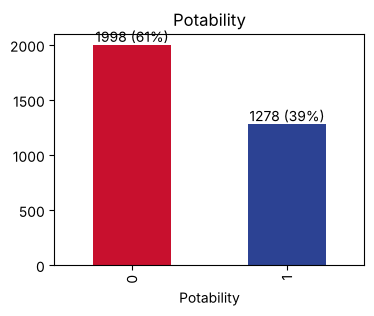

In [6]:
counts = df[TARGET].value_counts()
ax = counts.plot.bar(color=["#C8102E", "#2C4293"], figsize=(4, 3), title="Potability")
ax.bar_label(ax.containers[0], labels=[f"{n} ({n/len(df):.0%})" for n in counts]); plt.show()

> **Interpretación.** Desbalance moderado (61 % no potable / 39 % potable). Se usará partición **estratificada**, métricas insensibles al desbalance (ROC-AUC, precisión/recall) y `class_weight='balanced'`, en lugar de sobremuestreo antes de dividir (que filtra información al test).

### 1.6 EDA univariado — resumen estadístico de todas las variables

In [7]:
def resumen(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return pd.Series({"n": s.count(), "media": s.mean(), "mediana": s.median(), "de": s.std(),
                      "asimetría": s.skew(), "curtosis": s.kurt(),
                      "atípicos_IQR_%": 100 * ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).mean(),
                      "normalidad_p": stats.normaltest(s).pvalue})
df[FEATURES].apply(lambda s: resumen(s.dropna())).T.round(3)

,n,media,mediana,de,asimetría,curtosis,atípicos_IQR_%,normalidad_p
ph,2785.0,7.081,7.037,1.594,0.026,0.720,1.652,0.000
Hardness,3276.0,196.369,196.968,32.880,-0.039,0.616,2.534,0.000
Solids,3276.0,22014.093,20927.834,8768.571,0.622,0.443,1.435,0.000
Chloramines,3276.0,7.122,7.130,1.583,-0.012,0.590,1.862,0.000
Sulfate,2495.0,333.776,333.074,41.417,-0.036,0.648,1.643,0.000
Conductivity,3276.0,426.205,421.885,80.824,0.264,-0.277,0.336,0.000
Organic_carbon,3276.0,14.285,14.218,3.308,0.026,0.044,0.763,0.718
Trihalomethanes,3114.0,66.396,66.622,16.175,-0.083,0.239,1.060,0.008
Turbidity,3276.0,3.967,3.955,0.780,-0.008,-0.063,0.580,0.760


> **Interpretación.** Las 9 variables son continuas, casi simétricas (|asimetría| < 0.7) y con pocos atípicos (≤ 2.5 %). Solo `Organic_carbon` y `Turbidity` no rechazan la normalidad (p > 0.05). Las escalas difieren en órdenes de magnitud (`Solids` ≈ 22 000 vs `Turbidity` ≈ 4) → **escalar** es obligatorio para logística y SVM.

#### Ficha por variable: distribución por clase, boxplot y Q-Q

In [8]:
def ficha(v):
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
    sns.histplot(df, x=v, hue=TARGET, kde=True, stat="density", common_norm=False, ax=ax[0])
    sns.boxplot(df, x=TARGET, y=v, ax=ax[1])
    stats.probplot(df[v].dropna(), plot=ax[2]); ax[2].set_title("Q-Q normal")
    a, b = df.loc[df[TARGET] == 0, v].dropna(), df.loc[df[TARGET] == 1, v].dropna()
    fig.suptitle(f"{v} · Mann-Whitney p = {stats.mannwhitneyu(a, b).pvalue:.3f} · KS p = {stats.ks_2samp(a, b).pvalue:.3f}")
    plt.tight_layout(); plt.show()

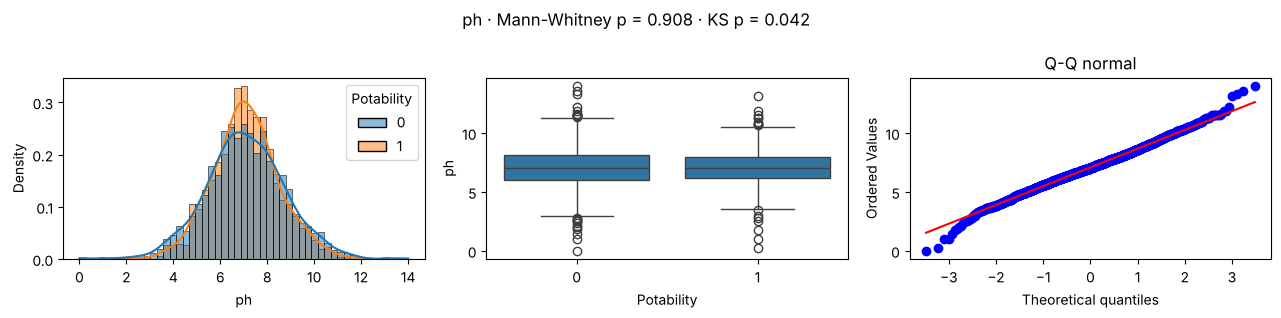

In [9]:
ficha("ph")

> **ph.** 15 % faltantes; rango 0–14 (extremos físicamente posibles pero sospechosos); 52 % fuera de 6.5–8.5. Las medianas por clase son iguales (Mann-Whitney p = 0.91), pero la clase potable es **menos dispersa** (DE 1.45 vs 1.68; KS p = 0.04): los valores extremos tienden a ser no potables → relación **no lineal**.

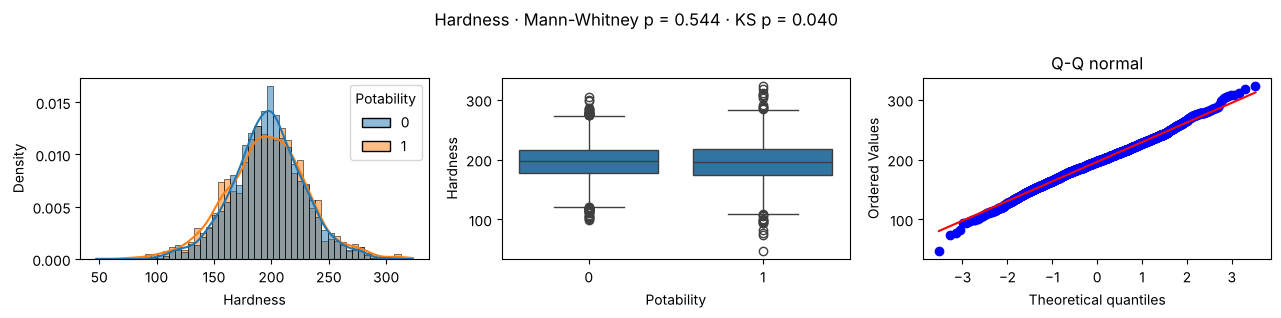

In [10]:
ficha("Hardness")

> **Hardness.** Sin faltantes; media 196 mg/L, distribución simétrica. Sin diferencia de ubicación entre clases (p = 0.54), aunque la clase potable es algo más dispersa (KS p = 0.04).

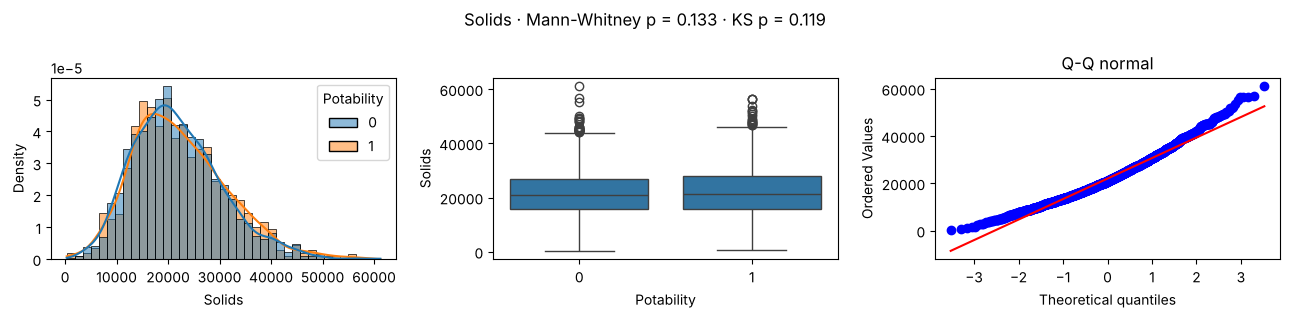

In [11]:
ficha("Solids")

> **Solids.** Media 22 014 mg/L: el 99.9 % supera el límite de 1000 mg/L, incompatible con agua potable → posible problema de unidades. Ligera asimetría positiva (0.62). Sin diferencia significativa entre clases (p = 0.13).

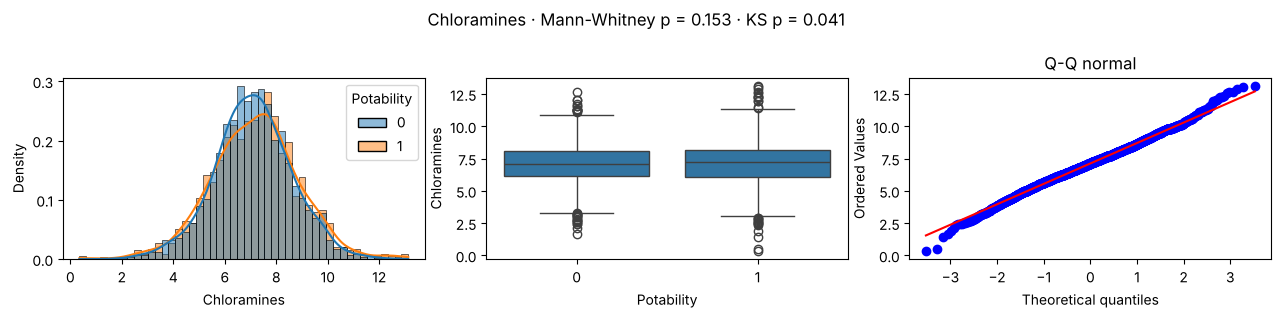

In [12]:
ficha("Chloramines")

> **Chloramines.** Media 7.1 ppm; el 97 % supera 4 ppm. Distribuciones por clase casi idénticas (p = 0.15).

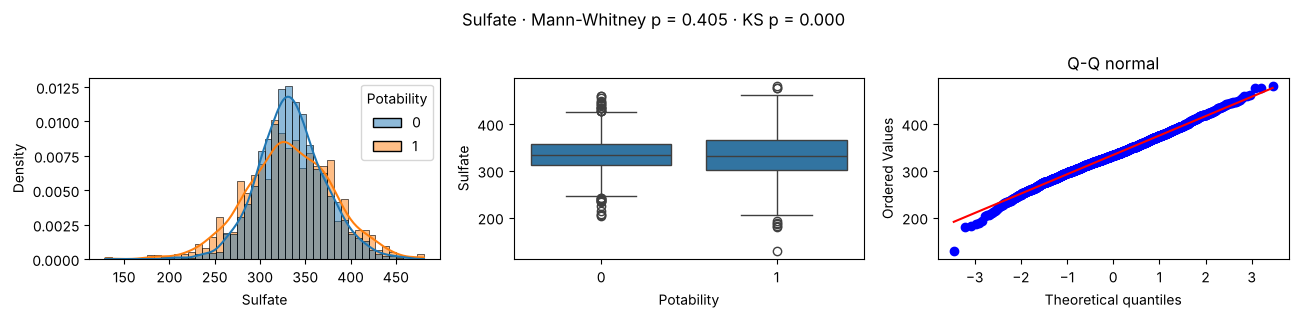

In [13]:
ficha("Sulfate")

> **Sulfate.** 24 % faltantes (la variable más incompleta). Medias iguales por clase (p = 0.41), pero la clase potable es **más dispersa** (DE 47.7 vs 36.7; KS p < 0.001) → señal en la varianza, no en la media.

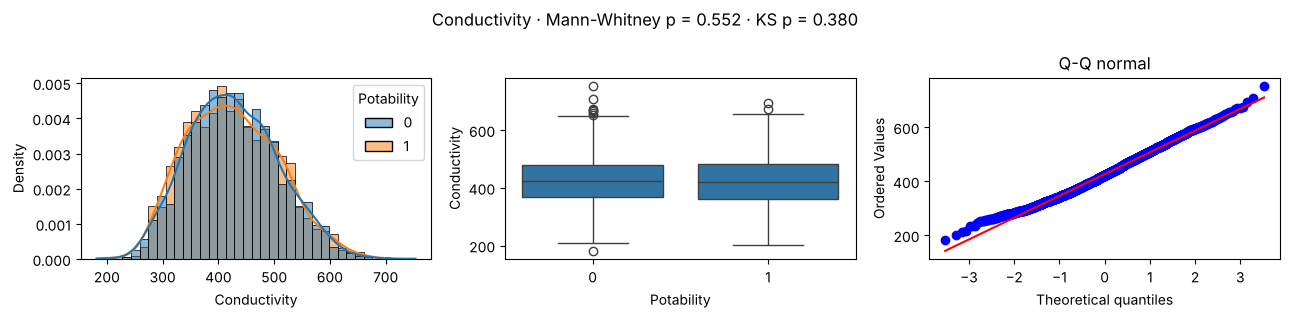

In [14]:
ficha("Conductivity")

> **Conductivity.** Media 426 μS/cm; 60 % supera 400. Leve asimetría positiva; sin diferencia entre clases (p = 0.55).

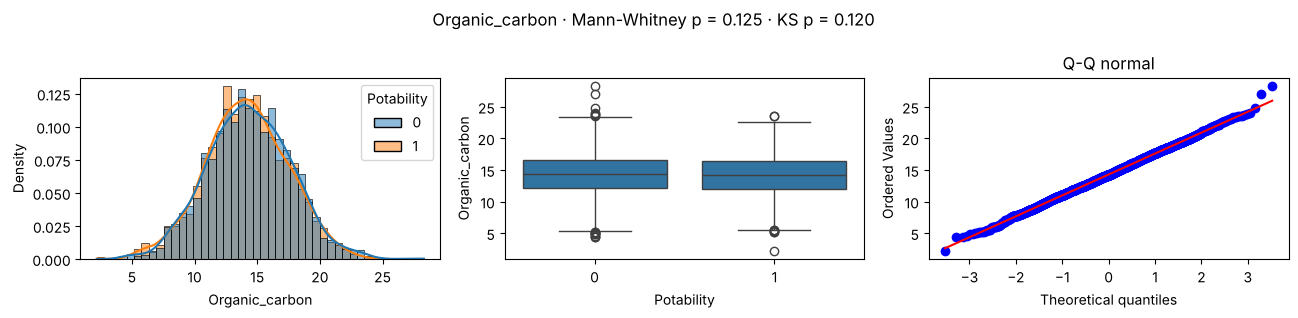

In [15]:
ficha("Organic_carbon")

> **Organic_carbon.** Aproximadamente normal (p = 0.72); el 100 % supera 2 mg/L. Sin diferencia entre clases (p = 0.13).

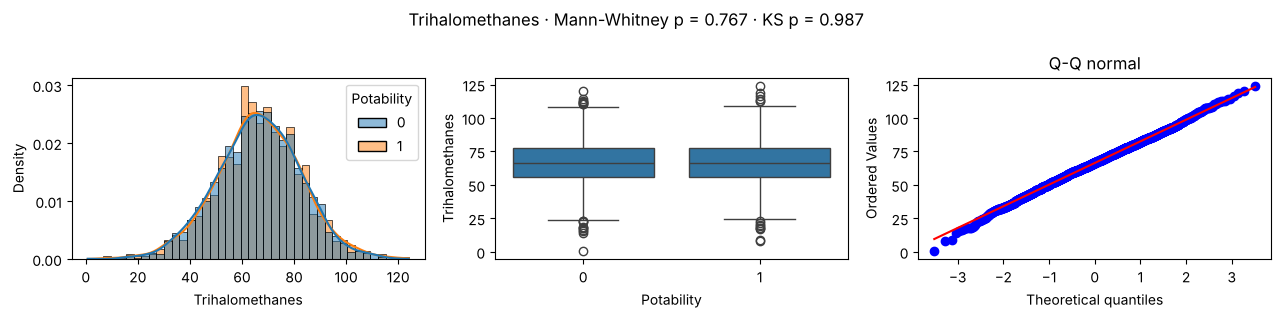

In [16]:
ficha("Trihalomethanes")

> **Trihalomethanes.** 5 % faltantes; media 66 μg/L; 19 % supera 80 μg/L. Distribuciones por clase prácticamente iguales (p = 0.77).

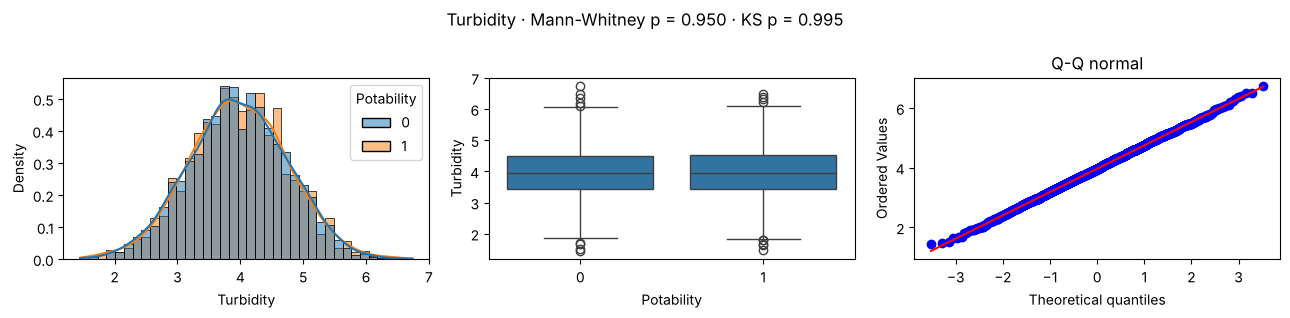

In [17]:
ficha("Turbidity")

> **Turbidity.** Normal (p = 0.76), media 3.97 NTU; 10 % supera 5 NTU. Distribuciones por clase idénticas (KS p = 0.99): por sí sola no aporta información.

### 1.7 EDA bivariado — cada variable vs. la variable objetivo

In [18]:
def vs_target(v):
    a, b = df.loc[df[TARGET] == 0, v].dropna(), df.loc[df[TARGET] == 1, v].dropna()
    U, p = stats.mannwhitneyu(a, b)
    return pd.Series({"media_0": a.mean(), "media_1": b.mean(), "de_0": a.std(), "de_1": b.std(),
                      "MW_p": p, "efecto_rb": 1 - 2*U/(len(a)*len(b)), "KS_p": stats.ks_2samp(a, b).pvalue})
bivar = pd.DataFrame({v: vs_target(v) for v in FEATURES}).T.round(3)
bivar.sort_values("KS_p")

,media_0,media_1,de_0,de_1,MW_p,efecto_rb,KS_p
Sulfate,334.564,332.567,36.746,47.693,0.405,-0.020,0.000
Hardness,196.733,195.801,31.058,35.547,0.544,-0.013,0.040
Chloramines,7.092,7.169,1.501,1.703,0.153,0.030,0.041
ph,7.085,7.074,1.683,1.448,0.908,-0.003,0.042
Solids,21777.491,22383.991,8543.069,9101.010,0.133,0.031,0.119
Organic_carbon,14.364,14.161,3.335,3.264,0.125,-0.032,0.120
Conductivity,426.730,425.384,80.047,82.048,0.552,-0.012,0.380
Trihalomethanes,66.304,66.540,16.079,16.327,0.767,0.006,0.987
Turbidity,3.966,3.968,0.780,0.781,0.950,0.001,0.995


> **Interpretación.** Ninguna variable difiere en **ubicación** entre clases (todos los Mann-Whitney p > 0.05; tamaños de efecto |r| < 0.04). Las únicas diferencias aparecen en la **forma/dispersión** (KS significativo en `Sulfate`, `ph`, `Hardness`, `Chloramines`). Hipótesis: los modelos lineales tendrán AUC ≈ 0.5 y los no lineales (SVM RBF, árbol) podrán aprovechar esas diferencias.

### 1.8 Mecanismo de los datos faltantes

In [19]:
pd.DataFrame({v: {"faltantes_%": 100*df[v].isna().mean(),
                  "%potable_si_falta": 100*df.loc[df[v].isna(), TARGET].mean(),
                  "chi2_p": stats.chi2_contingency(pd.crosstab(df[v].isna(), df[TARGET]))[1]}
              for v in ["ph", "Sulfate", "Trihalomethanes"]}).T.round(3)

,faltantes_%,%potable_si_falta,chi2_p
ph,14.988,36.049,0.159
Sulfate,23.840,37.516,0.348
Trihalomethanes,4.945,33.951,0.203


> **Interpretación.** La proporción de potables es similar con y sin dato (χ² p > 0.15): no hay evidencia de que la ausencia dependa de la clase → la **imputación por mediana**, ajustada solo con el conjunto de entrenamiento, es razonable.

### 1.9 EDA multivariado — correlaciones y estructura

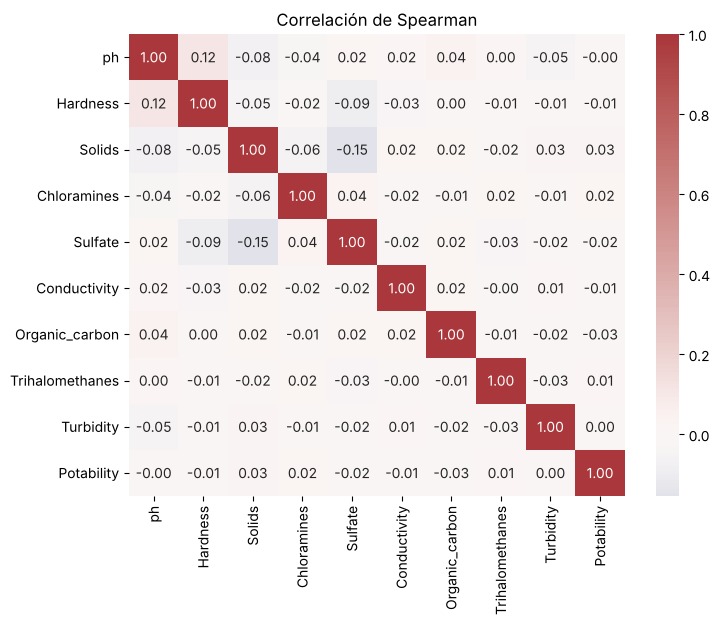

In [20]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(df.corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Correlación de Spearman"); plt.show()

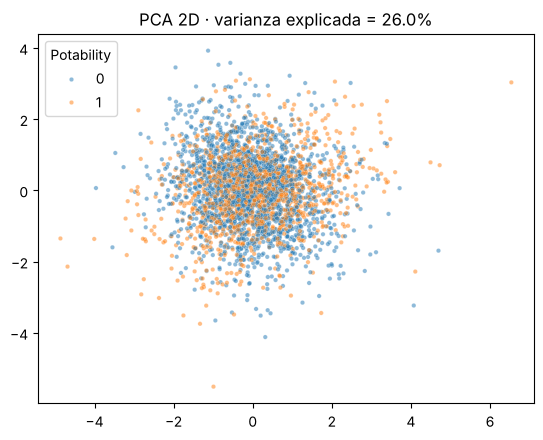

In [21]:
from sklearn.decomposition import PCA
Z = df[FEATURES].fillna(df[FEATURES].median()); Z = (Z - Z.mean()) / Z.std()
pc = PCA(2, random_state=SEED).fit(Z)
sns.scatterplot(x=pc.transform(Z)[:, 0], y=pc.transform(Z)[:, 1], hue=df[TARGET], s=10, alpha=.5)
plt.title(f"PCA 2D · varianza explicada = {pc.explained_variance_ratio_.sum():.1%}"); plt.show()

> **Interpretación.** Correlaciones muy débiles (|ρ| ≤ 0.15) → no hay redundancia ni multicolinealidad. El PCA explica poca varianza en 2D y las clases se superponen por completo: el problema es **difícil** y no linealmente separable.

### 1.10 Conclusiones del EDA y decisiones

| Hallazgo | Decisión |
|---|---|
| Faltantes MCAR en 3 variables | Imputar con la mediana dentro del pipeline (ajuste solo en train) |
| Escalas muy distintas | `StandardScaler` dentro del pipeline |
| Desbalance 61/39 | Partición estratificada + `class_weight="balanced"`; sin sobremuestreo previo |
| Sin señal lineal; diferencias en dispersión | Comparar modelos lineales (LPM, logística) vs no lineales (SVM RBF, árbol) |
| Etiquetas inconsistentes con límites OMS | Reportar como riesgo; criterio de éxito realista (AUC ≥ 0.65) |

In [22]:
# Registrar el entendimiento de datos en MLflow
with mlflow.start_run(run_name="01_data_understanding"):
    mlflow.log_input(mlflow.data.from_pandas(df, name="water_potability"), context="raw")
    mlflow.log_metrics({"n_rows": len(df), "pct_rows_missing": df.isna().any(axis=1).mean(), "pct_potable": df[TARGET].mean()})
    mlflow.log_table(bivar.reset_index(names="variable"), "eda/bivariate.json")

## Fase 2 · Preparación de datos

Primero se divide, después se preprocesa: así ninguna estadística del test (medianas, medias, desviaciones) participa en el entrenamiento.

In [23]:
from sklearn.model_selection import train_test_split
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"train {X_train.shape} · test {X_test.shape} · % potable train/test: {y_train.mean():.3f} / {y_test.mean():.3f}")

train (2620, 9) · test (656, 9) · % potable train/test: 0.390 / 0.390


In [24]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
prep = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]).set_output(transform="pandas")
Xtr = prep.fit_transform(X_train)          # ajusta solo con train
Xte = prep.transform(X_test)
Xtr.describe().loc[["mean", "std"]].round(2)

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
mean,0.0,0.0,0.0,0.0,0.0,-0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


> **Verificación (QA).** Tras el pipeline, cada variable de train tiene media 0 y DE 1, sin faltantes. El test se transforma con los parámetros de train.

## Fase 3 · Modelado

### 3.1 Línea base

In [25]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
dummy_auc = cross_val_score(DummyClassifier(strategy="prior"), Xtr, y_train, cv=cv, scoring="roc_auc")
print(f"Dummy AUC (CV) = {dummy_auc.mean():.3f}")

Dummy AUC (CV) = 0.500


### 3.2 Validación de supuestos por familia de modelos

| Modelo | Supuestos principales | Validación |
|---|---|---|
| Regresión lineal (LPM) | Linealidad, normalidad y homocedasticidad de residuos, independencia, sin multicolinealidad | Q-Q, Jarque-Bera, Breusch-Pagan, Durbin-Watson, VIF |
| Regresión logística | Linealidad del logit, sin multicolinealidad, sin observaciones muy influyentes, EPV suficiente | Box-Tidwell, VIF, distancia de Cook, EPV |
| SVM | Variables escaladas, elección de kernel adecuada | Media/DE tras escalar, CV lineal vs RBF |
| Árbol de decisión | Train/test con igual distribución, complejidad controlada | KS por variable, curva de validación |

#### 3.2.1 Regresión lineal (modelo de probabilidad lineal)

In [26]:
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import durbin_watson, jarque_bera
Xc = sm.add_constant(Xtr)
ols = sm.OLS(y_train.values, Xc).fit()
res, fit = ols.resid, ols.fittedvalues
print(f"R² = {ols.rsquared:.4f} · F p = {ols.f_pvalue:.3f} · predicciones fuera de [0,1]: {((fit<0)|(fit>1)).mean():.1%}")

R² = 0.0048 · F p = 0.186 · predicciones fuera de [0,1]: 0.0%


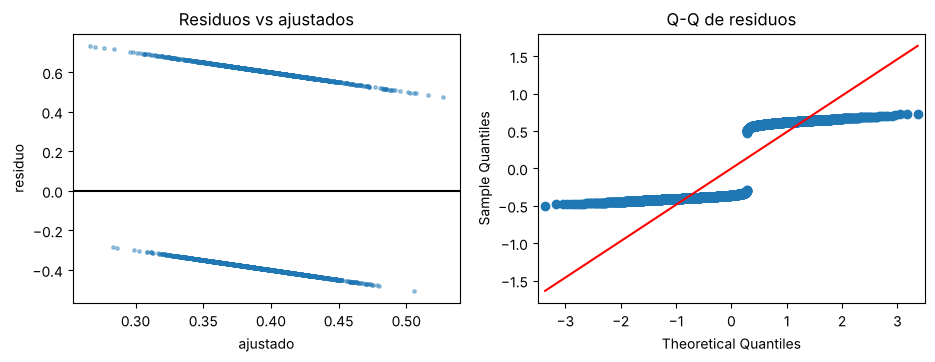

Jarque-Bera p = 7.95e-95 · Breusch-Pagan p = 0.014 · Durbin-Watson = 2.05


In [27]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].scatter(fit, res, s=6, alpha=.4); ax[0].axhline(0, c="k"); ax[0].set(xlabel="ajustado", ylabel="residuo", title="Residuos vs ajustados")
sm.qqplot(res, line="s", ax=ax[1]); ax[1].set_title("Q-Q de residuos"); plt.show()
print(f"Jarque-Bera p = {jarque_bera(res)[1]:.2e} · Breusch-Pagan p = {het_breuschpagan(res, Xc)[1]:.3f} · Durbin-Watson = {durbin_watson(res):.2f}")

> **Interpretación.**
> - **Normalidad ✗:** con un objetivo 0/1 los residuos forman **dos bandas** (Jarque-Bera p ≈ 0); se incumple por construcción.
> - **Homocedasticidad ✗:** Breusch-Pagan p ≈ 0.01; la varianza teórica es p(1−p).
> - **Independencia ✓:** Durbin-Watson ≈ 2.
> - **Linealidad ✗:** R² ≈ 0.
> - La regresión lineal queda como **referencia didáctica**; para estimar probabilidades se usa la logística.

In [28]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif = pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])], index=FEATURES)
vif.round(2).sort_values(ascending=False).to_frame("VIF").T

,Solids,Sulfate,ph,Hardness,Chloramines,Conductivity,Organic_carbon,Trihalomethanes,Turbidity
VIF,1.04,1.03,1.02,1.02,1.01,1.0,1.0,1.0,1.0


> **Interpretación.** Todos los VIF ≈ 1 (< 5): no hay multicolinealidad, coherente con las correlaciones de Spearman.

#### 3.2.2 Regresión logística

In [29]:
logit = sm.Logit(y_train.values, Xc).fit(disp=0)
epv = min(y_train.sum(), (1 - y_train).sum()) / len(FEATURES)
print(f"EPV = {epv:.0f} (≥ 10 ✓) · LLR p = {logit.llr_pvalue:.3f} · pseudo-R² = {logit.prsquared:.4f}")

EPV = 114 (≥ 10 ✓) · LLR p = 0.186 · pseudo-R² = 0.0036


In [30]:
# Box-Tidwell: término x·ln(x) significativo ⇒ el logit no es lineal en x (x desplazada a valores > 0)
Xpos = X_train.fillna(X_train.median()); Xpos = Xpos - Xpos.min() + 1
Xbt = Xpos.assign(**{f"{v}_xlnx": Xpos[v] * np.log(Xpos[v]) for v in FEATURES})
bt = sm.Logit(y_train.values, sm.add_constant(Xbt)).fit(disp=0, maxiter=200)
bt.pvalues.filter(like="_xlnx").round(3).to_frame("Box-Tidwell p").T

,ph_xlnx,Hardness_xlnx,Solids_xlnx,Chloramines_xlnx,Sulfate_xlnx,Conductivity_xlnx,Organic_carbon_xlnx,Trihalomethanes_xlnx,Turbidity_xlnx
Box-Tidwell p,0.0,0.007,0.978,0.018,0.0,0.605,0.395,0.361,0.793


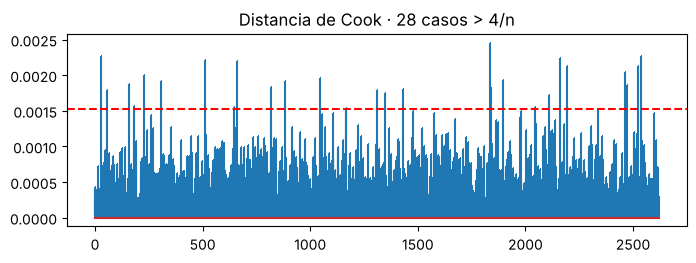

In [31]:
cook = sm.GLM(y_train.values, Xc, family=sm.families.Binomial()).fit().get_influence().cooks_distance[0]
plt.figure(figsize=(8, 2.5)); plt.stem(cook, markerfmt=","); plt.axhline(4/len(cook), c="r", ls="--")
plt.title(f"Distancia de Cook · {(cook > 4/len(cook)).sum()} casos > 4/n"); plt.show()

> **Interpretación.**
> - **EPV ≈ 114** (≥ 10 ✓) y VIF ≈ 1 (✓).
> - **Box-Tidwell** rechaza la linealidad del logit en `ph`, `Hardness`, `Chloramines` y `Sulfate` (p < 0.05) ✗: justo las variables cuya **dispersión** difiere entre clases en el EDA.
> - La prueba global de razón de verosimilitud no es significativa (p ≈ 0.19) y el pseudo-R² ≈ 0: un logit lineal no separa las clases.
> - Los casos con Cook > 4/n se revisan, no se eliminan automáticamente.
> - **Remedio:** términos cuadráticos o splines, o modelos no lineales (SVM RBF, árbol).

#### 3.2.3 SVM

In [32]:
from sklearn.svm import SVC
print("Media y DE tras escalar (≈ 0 y 1):", Xtr.mean().abs().max().round(3), Xtr.std().mean().round(3))
for kernel in ["linear", "rbf"]:
    s = cross_val_score(SVC(kernel=kernel, class_weight="balanced"), Xtr, y_train, cv=cv, scoring="roc_auc")
    print(f"SVM {kernel:6s} AUC (CV) = {s.mean():.3f} ± {s.std():.3f}")

Media y DE tras escalar (≈ 0 y 1): 0.0 1.0


SVM linear AUC (CV) = 0.521 ± 0.033


SVM rbf    AUC (CV) = 0.695 ± 0.018


> **Interpretación.** La SVM no supone distribuciones, pero **requiere escalado** (✓). El kernel lineal queda cerca de 0.5 y el RBF lo supera claramente: los datos no son linealmente separables, lo que justifica el kernel RBF.

#### 3.2.4 Árbol de decisión

In [33]:
ks = pd.Series({v: stats.ks_2samp(X_train[v].dropna(), X_test[v].dropna()).pvalue for v in FEATURES})
print("Variables con distinta distribución train/test (KS p < 0.05):", (ks < 0.05).sum(), "de", len(ks))

Variables con distinta distribución train/test (KS p < 0.05): 0 de 9


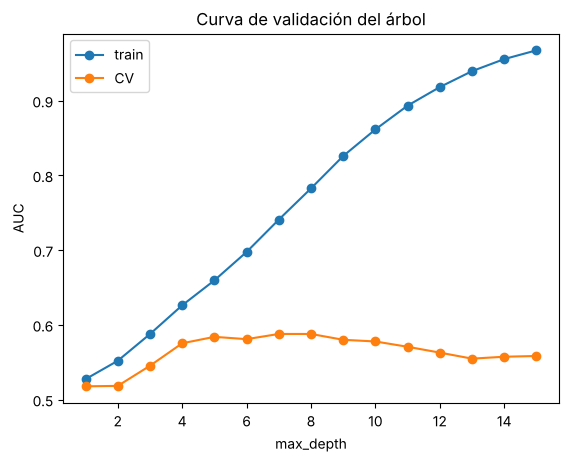

In [34]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import validation_curve
depths = range(1, 16)
tr, va = validation_curve(DecisionTreeClassifier(random_state=SEED), Xtr, y_train, param_name="max_depth", param_range=depths, cv=cv, scoring="roc_auc")
plt.plot(depths, tr.mean(1), "o-", label="train"); plt.plot(depths, va.mean(1), "o-", label="CV")
plt.xlabel("max_depth"); plt.ylabel("AUC"); plt.legend(); plt.title("Curva de validación del árbol"); plt.show()

> **Interpretación.** Train y test provienen de la misma distribución (KS no significativo). La curva muestra el **sobreajuste**: el AUC de entrenamiento sube hasta 1.0 mientras el de CV se estanca o cae → la profundidad debe controlarse (lo hará FLAML).

### 3.3 Búsqueda de hiperparámetros con FLAML

FLAML incluye la regresión logística (`lrl2`). La SVM con kernel RBF y el árbol se agregan como *learners* personalizados. La regresión lineal no tiene hiperparámetros: se evalúa directamente.

In [35]:
from flaml import tune
from flaml.automl.model import SKLearnEstimator

class SVMRBF(SKLearnEstimator):
    def __init__(self, task="binary", **config):
        super().__init__(task, **config)
        self.estimator_class = SVC
        self.params.pop("n_jobs", None)
        self.params.update(kernel="rbf", probability=True, class_weight="balanced")
    @classmethod
    def search_space(cls, data_size, task):
        return {"C": {"domain": tune.loguniform(0.01, 100), "init_value": 1.0},
                "gamma": {"domain": tune.loguniform(1e-3, 1), "init_value": 0.1}}

In [36]:
class DTree(SKLearnEstimator):
    def __init__(self, task="binary", **config):
        super().__init__(task, **config)
        self.estimator_class = DecisionTreeClassifier
        self.params.pop("n_jobs", None)
        self.params.update(class_weight="balanced")
    @classmethod
    def search_space(cls, data_size, task):
        return {"max_depth": {"domain": tune.randint(2, 15), "init_value": 4},
                "min_samples_leaf": {"domain": tune.randint(1, 60), "init_value": 10},
                "criterion": {"domain": tune.choice(["gini", "entropy"]), "init_value": "gini"}}

In [37]:
TIME_BUDGET = 120
automl = AutoML()
automl.add_learner("svm_rbf", SVMRBF); automl.add_learner("dtree", DTree)
with mlflow.start_run(run_name="03_flaml_search") as run_search:
    automl.fit(Xtr, y_train, task="classification", metric="roc_auc", eval_method="cv", n_splits=5,
               split_type="stratified", estimator_list=["lrl2", "svm_rbf", "dtree"], time_budget=TIME_BUDGET,
               seed=SEED, verbose=0, log_file_name=str(DIR_MLOPS / "flaml.log"), mlflow_logging=False)
    mlflow.log_params({"time_budget": TIME_BUDGET, "best_estimator": automl.best_estimator})
    mlflow.log_artifact(str(DIR_MLOPS / "flaml.log"))
automl.best_config_per_estimator

{'lrl2': {'C': np.float64(0.24999999999999997)},
 'svm_rbf': {'C': np.float64(1.605902163813749),
  'gamma': np.float64(0.11986906092148485)},
 'dtree': {'max_depth': 12,
  'min_samples_leaf': 10,
  'criterion': np.str_('entropy')}}

In [38]:
# La LPM se envuelve como clasificador: probabilidad = predicción lineal recortada a [0, 1]
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.linear_model import LinearRegression, LogisticRegression
class LinearProbabilityModel(ClassifierMixin, BaseEstimator):
    def fit(self, X, y):
        self.lr_ = LinearRegression().fit(X, y); self.classes_ = np.array([0, 1]); return self
    def predict_proba(self, X):
        p = np.clip(self.lr_.predict(X), 0, 1); return np.column_stack([1 - p, p])
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

In [39]:
# Modelos finales: cada familia con su mejor configuración de FLAML (la LPM no tiene hiperparámetros)
cfg = automl.best_config_per_estimator
models = {
    "Regresión lineal (LPM)": LinearProbabilityModel(),
    "Regresión logística": LogisticRegression(C=cfg["lrl2"]["C"], max_iter=1000, class_weight="balanced"),
    "SVM RBF": SVC(**cfg["svm_rbf"], kernel="rbf", probability=True, class_weight="balanced", random_state=SEED),
    "Árbol de decisión": DecisionTreeClassifier(**cfg["dtree"], class_weight="balanced", random_state=SEED)}

### 3.4 Validación cruzada estratificada 10 × 3

Cada modelo se evalúa en **30 particiones** de entrenamiento (10 folds × 3 repeticiones con distinta semilla). El conjunto de prueba no se usa aquí.
FLAML usó una CV de 5 folds solo para **buscar** hiperparámetros; esta CV **compara** los modelos ya configurados.

In [40]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
cv10x3 = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=SEED)
SCORING = {"AUC": "roc_auc", "Precisión": "precision", "Recall": "recall", "F1": "f1",
           "Exactitud": "accuracy", "Brier": "neg_brier_score"}
cv_res = {name: cross_validate(clone(m), Xtr, y_train, cv=cv10x3, scoring=SCORING, n_jobs=-1)
          for name, m in models.items()}

In [41]:
folds = pd.concat({name: pd.DataFrame({k: r[f"test_{k}"] for k in SCORING}) for name, r in cv_res.items()},
                  names=["modelo", "fold"]).reset_index(level=0)
folds["Brier"] = -folds["Brier"]                      # sklearn lo devuelve negativo
cv_table = folds.groupby("modelo").agg(["mean", "std"]).round(3)
cv_table.sort_values(("AUC", "mean"), ascending=False)

AUC        Precisión        Recall            F1  \
                         mean    std      mean    std   mean    std   mean   
modelo                                                                       
SVM RBF                 0.690  0.034     0.537  0.039  0.572  0.059  0.553   
Árbol de decisión       0.596  0.037     0.465  0.038  0.488  0.102  0.470   
Regresión lineal (LPM)  0.513  0.031     0.356  0.461  0.006  0.008  0.011   
Regresión logística     0.512  0.031     0.398  0.035  0.489  0.044  0.438   

                              Exactitud         Brier         
                          std      mean    std   mean    std  
modelo                                                        
SVM RBF                 0.043     0.641  0.031  0.212  0.008  
Árbol de decisión       0.055     0.579  0.032  0.275  0.021  
Regresión lineal (LPM)  0.015     0.611  0.004  0.239  0.002  
Regresión logística     0.037     0.511  0.035  0.251  0.002

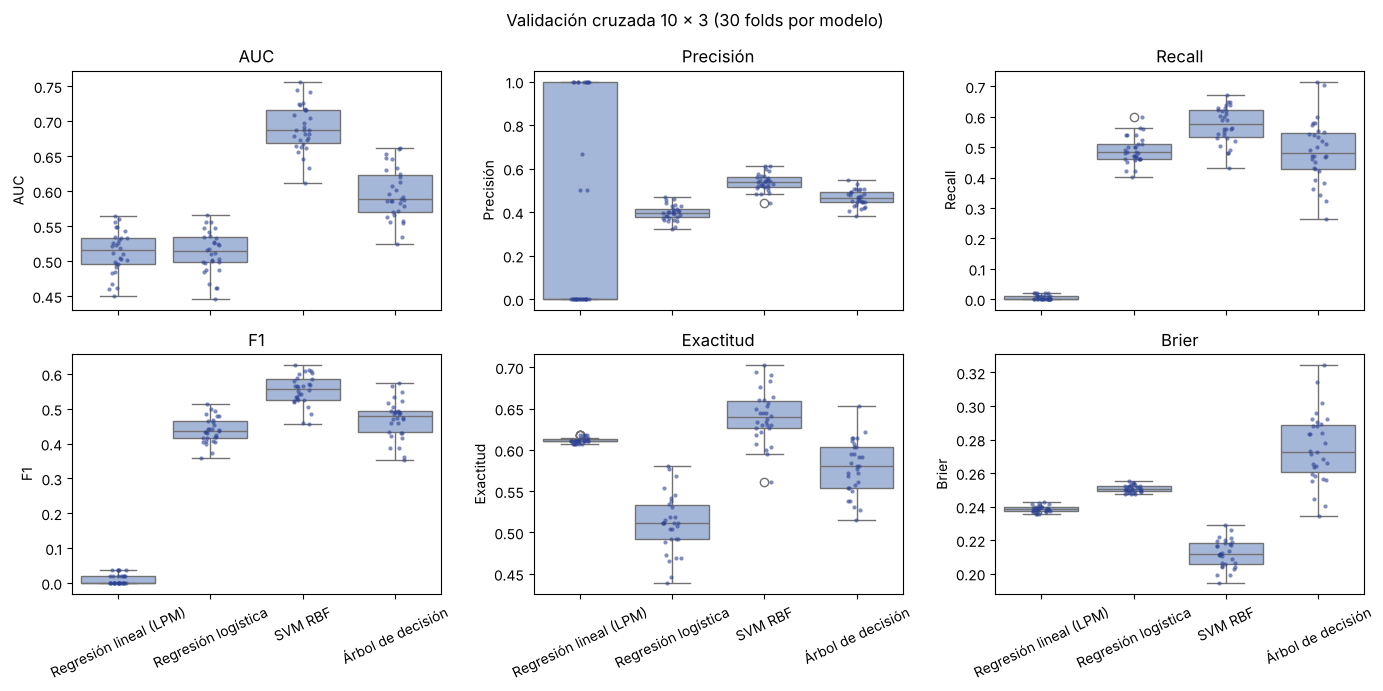

In [42]:
fig, axs = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for ax, metric in zip(axs.ravel(), SCORING):
    sns.boxplot(folds, x="modelo", y=metric, ax=ax, color="#9DB4E0")
    sns.stripplot(folds, x="modelo", y=metric, ax=ax, size=3, color="#2C4293", alpha=.6)
    ax.set_title(metric); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=25)
plt.suptitle("Validación cruzada 10 × 3 (30 folds por modelo)"); plt.tight_layout(); plt.show()

> **Cómo leer la gráfica:** cada punto es un fold; la caja muestra la mediana y el rango intercuartílico. Una caja alta y estrecha indica un modelo bueno **y** estable.
>
> **Interpretación (ejecución de referencia):**
> - **AUC:** el SVM RBF (≈ 0.69 ± 0.03) supera claramente al árbol (≈ 0.60) y a los modelos lineales (≈ 0.51, azar).
> - **La exactitud engaña:** la LPM logra 0.61 porque casi siempre predice "no potable" (recall ≈ 0.01). Es la proporción de la clase mayoritaria, no capacidad predictiva.
> - **Precisión de la LPM:** varía de 0 a 1 entre folds porque casi no predice positivos.
> - **Brier:** el SVM (0.21) tiene las probabilidades mejor calibradas; el árbol (0.28) es el peor, porque da pocas probabilidades distintas (una por hoja).

In [43]:
# ¿El mejor modelo supera a los demás? t-test corregido para CV repetida (Nadeau & Bengio, 2003)
def corrected_ttest(a, b, test_train_ratio=1/9):
    d = a - b; k = len(d)
    t = d.mean() / np.sqrt((1/k + test_train_ratio) * d.var(ddof=1))
    return t, 2 * stats.t.sf(abs(t), k - 1)
auc = folds.pivot(columns="modelo", values="AUC")
TOP = auc.mean().idxmax()
pd.DataFrame({m: dict(zip(["t", "p"], corrected_ttest(auc[TOP].values, auc[m].values)))
              for m in auc if m != TOP}).T.round(4).rename_axis(f"{TOP} vs")

,t,p
SVM RBF vs,,
Regresión lineal (LPM),17.2241,0.0
Regresión logística,17.2256,0.0
Árbol de decisión,4.8189,0.0


> **Interpretación.** Los folds de una CV repetida no son independientes (comparten datos de entrenamiento). Por eso se usa el t-test **corregido** de Nadeau & Bengio, que infla la varianza con el factor (1/k + n_test/n_train).
> El SVM es significativamente mejor que los otros tres modelos (p < 0.001): la diferencia no se explica por la variación entre particiones.

In [44]:
# Ajuste final de cada modelo con todo el conjunto de entrenamiento + registro en MLflow
cv_auc = {n: (cv_table.loc[n, ("AUC", "mean")], cv_table.loc[n, ("AUC", "std")]) for n in models}
with mlflow.start_run(run_id=run_search.info.run_id):
    for name, m in models.items():
        m.fit(Xtr, y_train)
        with mlflow.start_run(run_name=name, nested=True):
            mlflow.log_params({k: v for k, v in m.get_params().items() if v is not None})
            mlflow.log_metrics({f"cv_{k}_{s}": cv_table.loc[name, (k, s)] for k in SCORING for s in ["mean", "std"]})

## Fase 4 · Evaluación

### 4.1 Desempeño en test vs. criterios de éxito

In [45]:
from sklearn.metrics import roc_auc_score, average_precision_score, RocCurveDisplay, PrecisionRecallDisplay
score = lambda m, X: m.predict_proba(X)[:, 1]
test = pd.DataFrame({name: {"AUC_test": roc_auc_score(y_test, score(m, Xte)),
                            "AP_test": average_precision_score(y_test, score(m, Xte)),
                            "AUC_CV": cv_auc[name][0], "DE_CV": cv_auc[name][1]}
                     for name, m in models.items()}).T.round(3)
test["AUC≥0.65"] = np.where(test.AUC_test >= 0.65, "✓", "✗"); test["DE≤0.03"] = np.where(test.DE_CV <= 0.03, "✓", "✗")
test.sort_values("AUC_test", ascending=False)

,AUC_test,AP_test,AUC_CV,DE_CV,AUC≥0.65,DE≤0.03
SVM RBF,0.684,0.608,0.690,0.034,✓,✗
Árbol de decisión,0.605,0.517,0.596,0.037,✗,✗
Regresión logística,0.479,0.447,0.512,0.031,✗,✗
Regresión lineal (LPM),0.476,0.453,0.513,0.031,✗,✗


> **Interpretación.**
> - El AUC en test confirma lo observado en CV (SVM ≈ 0.68, árbol ≈ 0.61–0.63, lineales < 0.5): no hay sobreajuste a la partición de entrenamiento.
> - **Criterio de robustez:** ningún modelo cumple DE ≤ 0.03 con la CV 10 × 3; el SVM queda en ≈ 0.033.
> - **AP** (precisión promedio) es el área bajo la curva precisión-recall; su línea base es la proporción de potables (0.39).

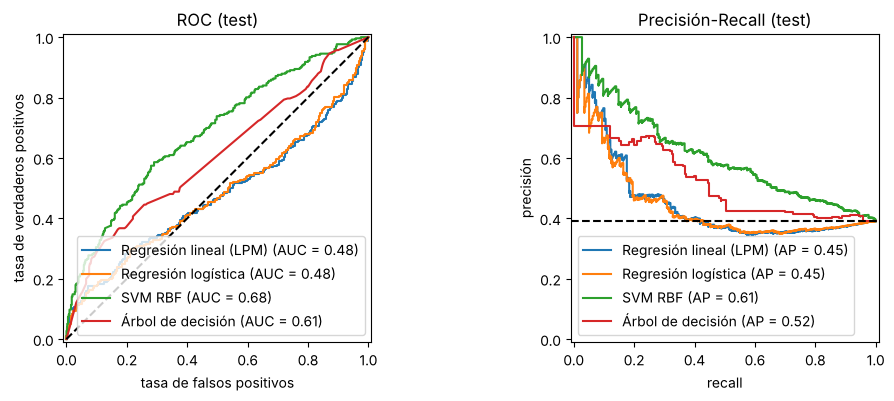

In [46]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, m in models.items():
    RocCurveDisplay.from_predictions(y_test, score(m, Xte), name=name, ax=ax[0])
    PrecisionRecallDisplay.from_predictions(y_test, score(m, Xte), name=name, ax=ax[1])
ax[0].plot([0, 1], [0, 1], "k--"); ax[1].axhline(y_test.mean(), c="k", ls="--")
ax[0].set(title="ROC (test)", xlabel="tasa de falsos positivos", ylabel="tasa de verdaderos positivos")
ax[1].set(title="Precisión-Recall (test)", xlabel="recall", ylabel="precisión"); plt.show()

> **Cómo leer la gráfica:**
> - **ROC:** la diagonal es el azar; cuanto más se aleja la curva hacia la esquina superior izquierda, mejor ordena el modelo las muestras.
> - **Precisión-recall:** la línea punteada es la proporción de potables (0.39).
>
> **Interpretación:**
> - Los modelos lineales siguen la diagonal.
> - El SVM domina en casi todo el rango, sobre todo en la zona de **alta precisión y bajo recall** (izquierda de la curva PR), que es la que interesa al negocio.

In [47]:
BEST = test.AUC_test.idxmax(); best = models[BEST]
print("Mejor modelo:", BEST)

Mejor modelo: SVM RBF


### 4.2 Umbral de decisión (elegido en train con predicciones fuera de pliegue, no en test)

In [48]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve
oof = cross_val_predict(clone(best), Xtr, y_train, cv=StratifiedKFold(10, shuffle=True, random_state=SEED),
                        method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
ok = np.where(prec[:-1] >= 0.70)[0]
THRESHOLD = thr[ok[np.argmax(rec[ok])]] if len(ok) else 0.5

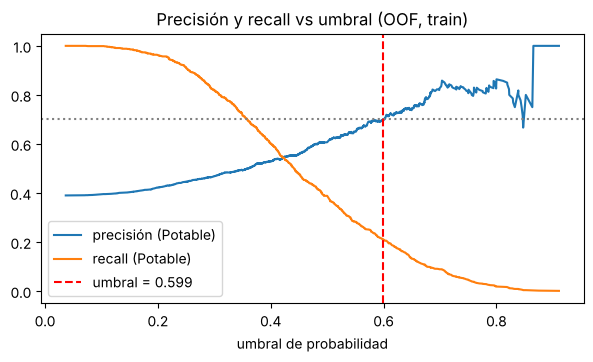

In [49]:
plt.figure(figsize=(7, 3.5))
plt.plot(thr, prec[:-1], label="precisión (Potable)"); plt.plot(thr, rec[:-1], label="recall (Potable)")
plt.axhline(0.70, c="gray", ls=":"); plt.axvline(THRESHOLD, c="r", ls="--", label=f"umbral = {THRESHOLD:.3f}")
plt.xlabel("umbral de probabilidad"); plt.legend(); plt.title("Precisión y recall vs umbral (OOF, train)"); plt.show()

> **Cómo leer la gráfica:** al subir el umbral, el modelo declara "potable" solo cuando está más seguro: sube la precisión y baja el recall.
> El umbral se fija donde la precisión alcanza 0.70 (línea punteada) con el mayor recall posible (≈ 0.60). Se calcula con predicciones **fuera de pliegue** en train, para no usar el test.

{'precision_potable': 0.743, 'recall_potable': 0.215} → criterio operativo ✓


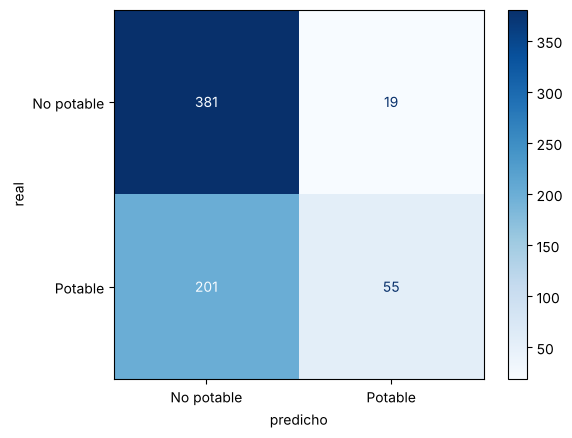

In [50]:
from sklearn.metrics import precision_score, recall_score, ConfusionMatrixDisplay
y_hat = (score(best, Xte) >= THRESHOLD).astype(int)
op = {"precision_potable": precision_score(y_test, y_hat, zero_division=0), "recall_potable": recall_score(y_test, y_hat)}
print({k: round(v, 3) for k, v in op.items()}, "→ criterio operativo", "✓" if op["precision_potable"] >= 0.70 else "✗")
ConfusionMatrixDisplay.from_predictions(y_test, y_hat, display_labels=["No potable", "Potable"], cmap="Blues")
plt.xlabel("predicho"); plt.ylabel("real"); plt.show()

> **Interpretación (umbral ≈ 0.60):**
> - **Errores graves:** solo ≈ 20 muestras no potables se declaran potables (falsos positivos), por eso la precisión es ≈ 0.75.
> - **Costo:** ≈ 200 muestras potables van al laboratorio sin necesidad (falsos negativos).
> - El modelo **reduce el riesgo, no la carga de laboratorio**: ese es el compromiso del criterio operativo.

### 4.3 Robustez

In [51]:
rng = np.random.default_rng(SEED); p_best = score(best, Xte); yt = y_test.values
boot = [roc_auc_score(yt[i], p_best[i]) for i in (rng.integers(0, len(yt), len(yt)) for _ in range(1000))]
ci = np.percentile(boot, [2.5, 97.5]); print(f"AUC test {BEST}: IC 95 % bootstrap = [{ci[0]:.3f}, {ci[1]:.3f}]")

AUC test SVM RBF: IC 95 % bootstrap = [0.642, 0.728]


### 4.4 Interpretabilidad

| Método | Pregunta que responde | Modelo |
|---|---|---|
| Odds ratios con IC 95 % | ¿Cómo cambia el riesgo con cada variable (efecto lineal)? | Regresión logística |
| Reglas del árbol | ¿Qué condiciones llevan a "potable"? | Árbol de decisión |
| Importancia por permutación | ¿Qué variables usa realmente el modelo? | Todos |
| PDP / ICE | ¿Cómo cambia la probabilidad al mover una variable? | Mejor modelo |

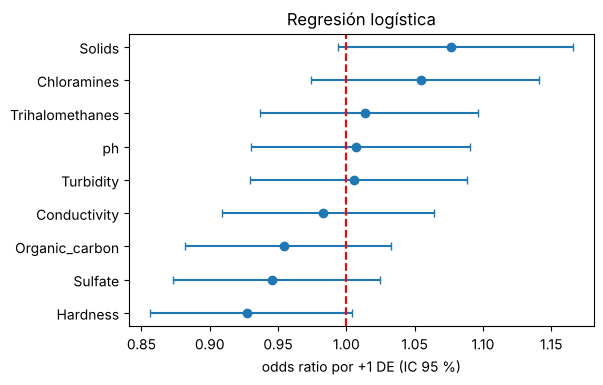

In [52]:
ors = pd.DataFrame({"OR": np.exp(logit.params[1:]), "low": np.exp(logit.conf_int()[0][1:]),
                    "high": np.exp(logit.conf_int()[1][1:])}).sort_values("OR")
plt.figure(figsize=(6, 3.8)); plt.errorbar(ors.OR, ors.index, xerr=[ors.OR - ors.low, ors.high - ors.OR], fmt="o", capsize=3)
plt.axvline(1, c="r", ls="--"); plt.xlabel("odds ratio por +1 DE (IC 95 %)"); plt.title("Regresión logística"); plt.show()

> **Cómo leer la gráfica:** cada punto es el cambio multiplicativo en los *odds* de potabilidad al aumentar la variable en 1 desviación estándar; la barra es el IC 95 %. Si la barra cruza 1 (línea roja), el efecto lineal no es significativo.
>
> **Interpretación:** **todos** los intervalos cruzan 1. Ninguna variable tiene un efecto lineal sobre el logit, coherente con Box-Tidwell y con el EDA: la señal está en los extremos (forma no lineal), no en la tendencia.

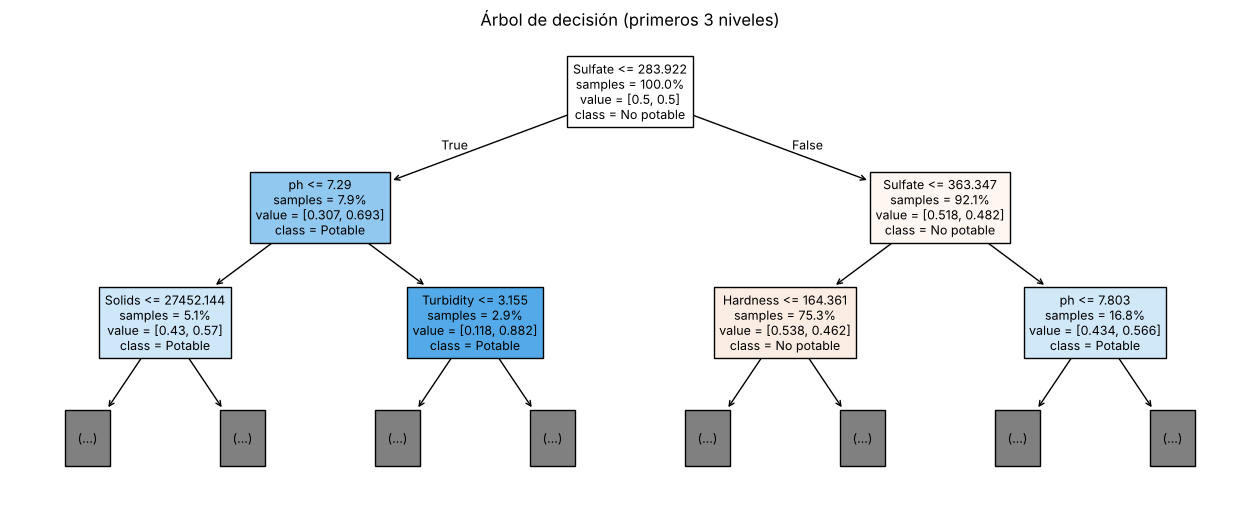

In [53]:
from sklearn.tree import plot_tree, export_text
# El árbol no depende de la escala: se reajusta con datos imputados SIN escalar para leer umbrales en unidades reales
X_imp = pd.DataFrame(prep.named_steps["imputer"].transform(X_train), columns=FEATURES)
tree = clone(models["Árbol de decisión"]).fit(X_imp, y_train)
plt.figure(figsize=(16, 6))
plot_tree(tree, feature_names=FEATURES, class_names=["No potable", "Potable"], max_depth=2, filled=True, proportion=True, impurity=False, fontsize=9)
plt.title("Árbol de decisión (primeros 3 niveles)"); plt.show()

> **Cómo leer el árbol:** cada nodo muestra la regla, el % de muestras que llegan a él y la proporción ponderada [no potable, potable] (con `class_weight="balanced"` la raíz parte de 0.5/0.5). Más azul = más potable.
>
> **Interpretación (ejecución de referencia; los umbrales pueden cambiar entre ejecuciones):**
> - La raíz separa los **sulfatos bajos** (≤ ≈ 284 mg/L, solo ≈ 8 % de las muestras), que son mayoritariamente potables (≈ 70 %).
> - En sulfatos altos (> ≈ 363 mg/L) con `ph` moderado vuelve a predominar la clase potable.
> - Las reglas confirman que la señal está en los **extremos** de `Sulfate` y `ph`, no en una tendencia lineal.

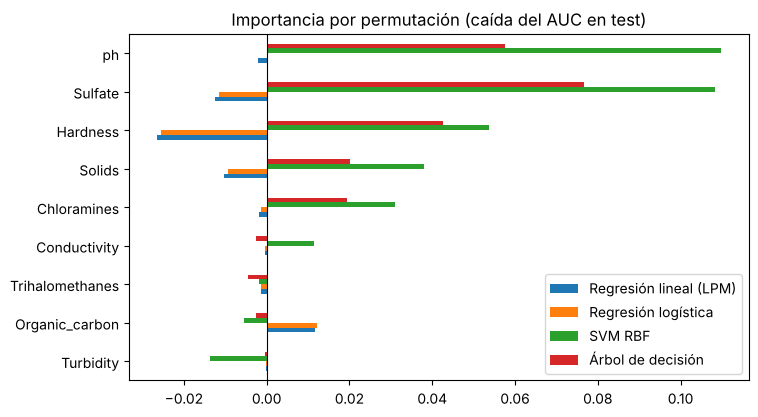

In [54]:
from sklearn.inspection import permutation_importance
imp = pd.DataFrame({name: permutation_importance(m, Xte, y_test, scoring="roc_auc", n_repeats=20, random_state=SEED).importances_mean
                    for name, m in models.items()}, index=FEATURES)
imp.loc[imp[BEST].sort_values().index].plot.barh(figsize=(8, 4.5), title="Importancia por permutación (caída del AUC en test)")
plt.axvline(0, c="k", lw=.8); plt.show()

> **Cómo leer la gráfica:** cuánto cae el AUC en test al barajar cada variable. Una caída de 0 (o negativa) significa que el modelo no usa esa variable.
>
> **Interpretación:**
> - **SVM:** depende de `ph`, `Sulfate` y `Hardness`, en ese orden. Son justo las variables con distinta **dispersión** entre clases en el EDA (prueba KS).
> - **Árbol:** usa las mismas tres.
> - **Lineales:** importancias ≈ 0; no aprovechan ninguna variable.

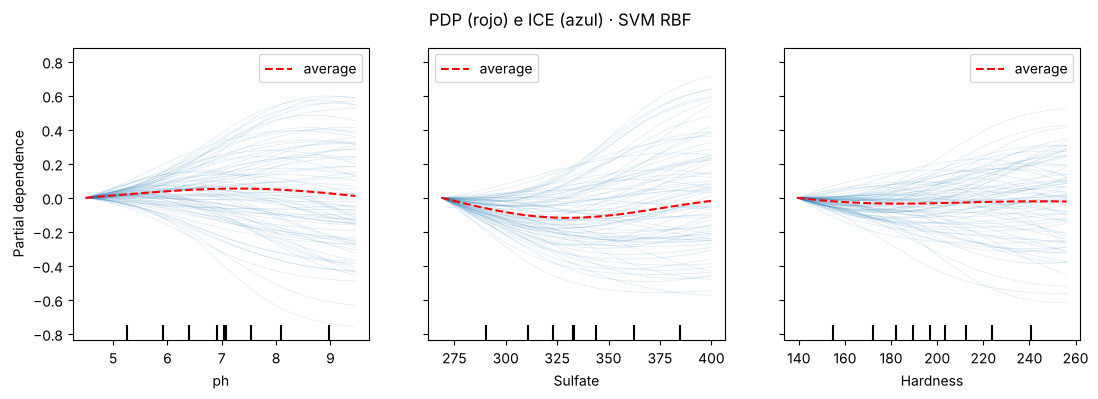

In [55]:
from sklearn.inspection import PartialDependenceDisplay
final = Pipeline([("prep", prep), ("model", best)])           # recibe datos en unidades originales
X_pdp = X_test.fillna(X_train.median())
top3 = imp[BEST].sort_values(ascending=False).index[:3].tolist()
PartialDependenceDisplay.from_estimator(final, X_pdp, top3, kind="both", subsample=80, random_state=SEED,
                                        centered=True, ice_lines_kw={"alpha": .15}, pd_line_kw={"color": "r"})
plt.gcf().set_size_inches(13, 3.8); plt.suptitle(f"PDP (rojo) e ICE (azul) · {BEST}"); plt.show()

> **Cómo leer la gráfica:**
> - **ICE (azul):** cada línea es una muestra; muestra cómo cambia **su** probabilidad al mover la variable, dejando fijas las demás.
> - **PDP (rojo):** el promedio de las líneas ICE. Las curvas están centradas en el valor mínimo.
>
> **Interpretación:**
> - La PDP casi plana con ICE en **abanico** (unas suben, otras bajan) indica que el efecto de `ph`, `Sulfate` y `Hardness` **depende de las otras variables**: hay interacciones.
> - Por eso estas variables son importantes por permutación, pero no muestran una tendencia promedio.
> - Una regla simple de umbral sobre una sola variable no basta.

In [56]:
with mlflow.start_run(run_name="04_evaluation"):
    mlflow.log_table(test.reset_index(names="model"), "evaluation/test_metrics.json")
    mlflow.log_table(cv_table.round(4).reset_index().astype(str), "evaluation/cv_10x3.json")
    mlflow.log_table(imp.reset_index(names="variable"), "evaluation/permutation_importance.json")
    mlflow.log_metrics({"best_auc_test": test.loc[BEST, "AUC_test"], "auc_ci_low": ci[0], "auc_ci_high": ci[1],
                        "threshold": THRESHOLD, **op})
    mlflow.log_param("best_model", BEST)

> **Decisión (go / no-go)** — ejecución de referencia (los valores pueden variar levemente con el presupuesto de FLAML):
>
> | Criterio | Resultado (SVM RBF) | Cumple |
> |---|---|---|
> | AUC test ≥ 0.65 y > línea base | ≈ 0.68 (IC 95 % ≈ 0.64–0.73) vs 0.50; mejor que los otros 3 modelos (p < 0.001) | ✓ |
> | Precisión *Potable* ≥ 0.70 | ≈ 0.75, con recall ≈ 0.21 | ✓ |
> | DE del AUC en CV 10 × 3 ≤ 0.03 | ≈ 0.033 | ✗ |
> | Trazabilidad en MLflow | runs 01–06 + modelo registrado | ✓ |
>
> - **No-go para producción tal como está:** falla el criterio de robustez (por poco).
> - **Siguiente iteración (volver a las fases 2–3):** más datos, ingeniería de variables (p. ej. distancia de `ph` a 7, que captura los extremos) o ensambles.
> - Sirve como **prototipo** para priorizar muestras. Nunca para certificar potabilidad: las etiquetas no concuerdan con los límites OMS.

## Fase 5 · Despliegue

El modelo se empaqueta **con su preprocesamiento** (imputación + escalado) para que reciba datos crudos.

In [57]:
from mlflow.models import infer_signature
signature = infer_signature(X_train, final.predict_proba(X_train)[:, 1])
with mlflow.start_run(run_name="05_deployment") as run_dep:
    mlflow.log_params({"model": BEST, "threshold": THRESHOLD})
    info = mlflow.sklearn.log_model(final, name="model", signature=signature, input_example=X_train.head(3), serialization_format="cloudpickle",
                                    registered_model_name="water_potability_classifier")
print(info.model_uri)

2026/10/26 14:43:21 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


models:/m-19a26c366d2240889112784ec5a02476


Successfully registered model 'water_potability_classifier'.
Created version '1' of model 'water_potability_classifier'.


In [58]:
from mlflow import MlflowClient
client = MlflowClient()
version = client.get_latest_versions("water_potability_classifier")[0].version
client.set_registered_model_alias("water_potability_classifier", "champion", version)
loaded = mlflow.sklearn.load_model("models:/water_potability_classifier@champion")
nuevas = X_test.head(5)
pd.DataFrame({"p_potable": loaded.predict_proba(nuevas)[:, 1].round(3),
              "decisión": np.where(loaded.predict_proba(nuevas)[:, 1] >= THRESHOLD, "Baja prioridad", "Prioridad alta: laboratorio")})

,p_potable,decisión
0,0.689,Baja prioridad
1,0.097,Prioridad alta: laboratorio
2,0.283,Prioridad alta: laboratorio
3,0.225,Prioridad alta: laboratorio
4,0.384,Prioridad alta: laboratorio


## Fase 6 · Monitoreo y mantenimiento

Se simula un lote nuevo con un **corrimiento de pH** (p. ej. un cambio en el tratamiento) y se detecta con la prueba KS y el índice PSI.

In [59]:
def psi(ref, new, bins=10):
    edges = np.unique(np.quantile(ref.dropna(), np.linspace(0, 1, bins + 1)))
    r = np.histogram(ref.dropna(), edges)[0] / ref.notna().sum() + 1e-6
    n = np.histogram(new.dropna(), edges)[0] / new.notna().sum() + 1e-6
    return np.sum((n - r) * np.log(n / r))

batch = X_test.copy(); batch["ph"] = batch["ph"] + 1.0          # lote con deriva simulada
drift = pd.DataFrame({v: {"KS_p": stats.ks_2samp(X_train[v].dropna(), batch[v].dropna()).pvalue,
                          "PSI": psi(X_train[v], batch[v])} for v in FEATURES}).T.round(3)
drift["alerta"] = np.where((drift.KS_p < 0.01) | (drift.PSI > 0.2), "⚠ deriva", "ok"); drift

,KS_p,PSI,alerta
ph,0.000,0.351,⚠ deriva
Hardness,0.572,0.013,ok
Solids,0.852,0.007,ok
Chloramines,0.751,0.012,ok
Sulfate,0.486,0.018,ok
Conductivity,0.969,0.010,ok
Organic_carbon,0.126,0.029,ok
Trihalomethanes,0.356,0.018,ok
Turbidity,0.751,0.017,ok


> **Interpretación.** Solo `ph` dispara la alerta (KS p ≈ 0 y PSI = 0.35 > 0.2), que es la deriva simulada; las demás variables siguen estables.
> Como `ph` es la variable más importante del modelo, esta deriva obliga a **revisar el proceso de medición** antes de seguir usando las predicciones.

In [60]:
with mlflow.start_run(run_name="06_monitoring"):
    mlflow.log_table(drift.reset_index(names="variable"), "monitoring/drift_report.json")
    mlflow.log_metric("n_features_drift", (drift.alerta != "ok").sum())

**Plan de mantenimiento**

| Disparador | Acción |
|---|---|
| PSI > 0.2 o KS p < 0.01 en alguna variable | Revisar sensores / proceso; evaluar reentrenamiento |
| AUC en datos etiquetados recientes < 0.65 | Reentrenar con datos nuevos y repetir las fases 2–4 |
| Cambio en normas OMS o en el laboratorio | Volver a la fase 1 (redefinir objetivo y etiquetas) |

### Ver los experimentos

```bash
mlflow ui --backend-store-uri sqlite:///mlops/mlflow.db
```
Ejecútelo desde la carpeta del notebook y abra http://127.0.0.1:5000.

### Referencias
- Studer, S. et al. (2021). *Towards CRISP-ML(Q): A Machine Learning Process Model with Quality Assurance Methodology*. Machine Learning and Knowledge Extraction, 3(2), 392–413.
- Wang, C. et al. (2021). *FLAML: A Fast and Lightweight AutoML Library*. MLSys.
- Russell, S. & Norvig, P. (2022). *Artificial Intelligence: A Modern Approach* (4th ed.), cap. 19.